# Practical Assignment: Clustering Algorithms

**Name: Sanket Kongare**  
**PRN: 202401040057**

**Batch: A1**  

**Div: A**
  
  **Roll No: 18**  

---

## 1. Introduction

In this notebook, we will work with a real-world dataset to find hidden groups or patterns among customers. This process is called **Clustering** (an unsupervised machine learning technique).

We will use the popular **Mall Customers Dataset**, which contains information about people visiting a mall, such as their age, gender, annual income, and spending score. Our goal is to group these customers so that the mall management can target them with specific marketing campaigns.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Load the dataset directly from a public URL
url = "https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv"
df = pd.read_csv(url)

# Rename columns for easier access
df.rename(columns={'Annual Income (k$)': 'Income', 'Spending Score (1-100)': 'Spending_Score'}, inplace=True)

print("Dataset loaded successfully! Here is a quick look:")
display(df.head())

Dataset loaded successfully! Here is a quick look:


,CustomerID,Gender,Age,Income,Spending_Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 2. Exploring and Preparing the Data

Before we start grouping, let's look at how our data is distributed. We will focus on two key features for our clustering: **Income** and **Spending Score**.

       CustomerID         Age      Income  Spending_Score
count  200.000000  200.000000  200.000000      200.000000
mean   100.500000   38.850000   60.560000       50.200000
std     57.879185   13.969007   26.264721       25.823522
min      1.000000   18.000000   15.000000        1.000000
25%     50.750000   28.750000   41.500000       34.750000
50%    100.500000   36.000000   61.500000       50.000000
75%    150.250000   49.000000   78.000000       73.000000
max    200.000000   70.000000  137.000000       99.000000


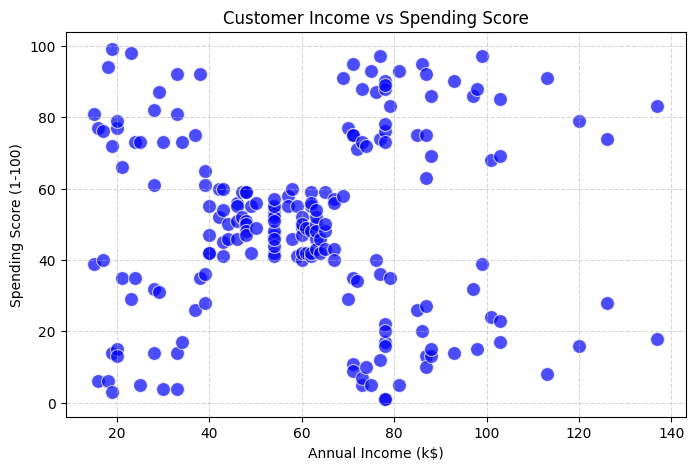

In [ ]:
# Let's check basic stats
print(df.describe())

# Visualizing the relationship between Income and Spending Score
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Income', y='Spending_Score', s=100, color='blue', alpha=0.7)
plt.title('Customer Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Explanation of the Scatter Plot
Looking at the graph above, we can naturally see some visual groups or "clouds" of data points. For example:
* People with low income and low spending score.
* People with low income but high spending score.
* People in the middle (average income, average spending).
* People with high income and low spending score.
* People with high income and high spending score.

Let's extract these features and scale them so that our algorithms work accurately.

In [ ]:
# Selecting the features for clustering
X = df[['Income', 'Spending_Score']]

# Standardizing the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 3. Algorithm 1: K-Means Clustering

K-Means needs us to specify the number of clusters (K) in advance. To find the best number of clusters, we use the **Elbow Method**.

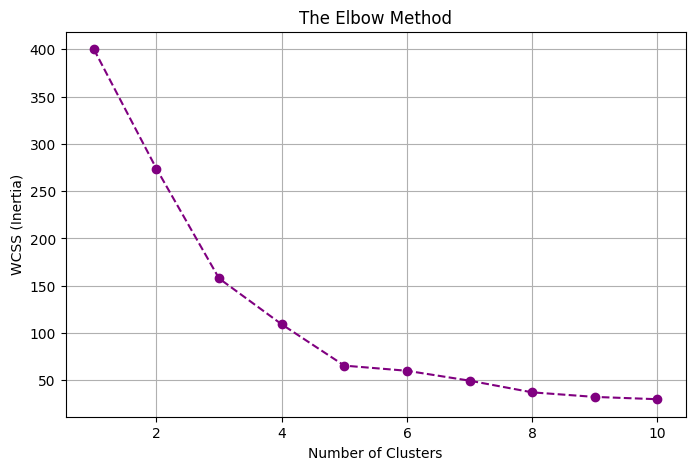

In [ ]:
# Finding optimal K using Elbow Method
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--', color='purple')
plt.title('The Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.show()

### Explanation of the Elbow Plot
The WCSS (Within-Cluster Sum of Squares) measures how close the points are within a cluster. As the number of clusters increases, WCSS drops. We look for an "elbow" point where the rate of decrease slows down significantly. In this graph, the elbow appears around **5 clusters**.

Let's train our K-Means model with 5 clusters.

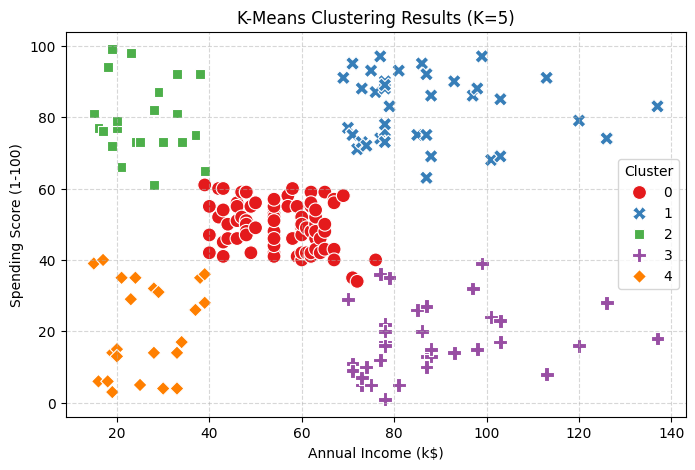

In [ ]:
# Fitting K-Means to the dataset
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Adding the cluster labels back to our original dataframe
df['KMeans_Cluster'] = kmeans_labels

# Plotting the final K-Means clusters
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Income', y='Spending_Score', hue='KMeans_Cluster', palette='Set1', s=100, style='KMeans_Cluster')
plt.title('K-Means Clustering Results (K=5)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 4. Algorithm 2: Hierarchical Clustering

Let's apply another algorithm called **Agglomerative (Hierarchical) Clustering** to see if we get similar results.

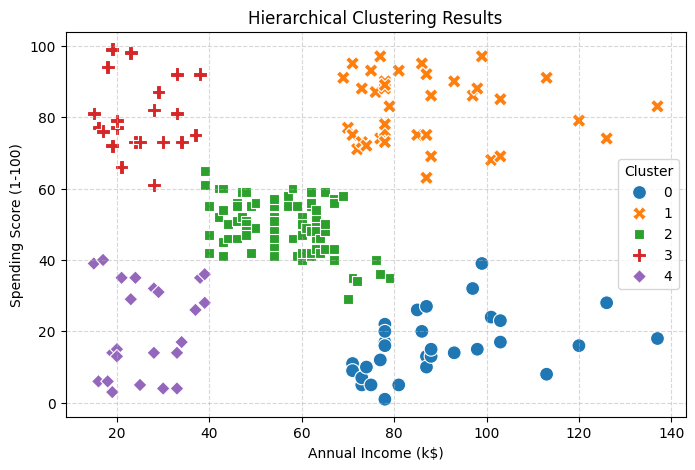

In [ ]:
# Fitting Agglomerative Clustering with 5 clusters
hierarchical = AgglomerativeClustering(n_clusters=5)
hierarchical_labels = hierarchical.fit_predict(X_scaled)

df['Hierarchical_Cluster'] = hierarchical_labels

# Plotting the Hierarchical clusters
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Income', y='Spending_Score', hue='Hierarchical_Cluster', palette='tab10', s=100, style='Hierarchical_Cluster')
plt.title('Hierarchical Clustering Results')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 5. Evaluation and Comparison

To verify our clusters scientifically, we use two popular metrics:
1. **Silhouette Score**: Ranges from -1 to 1. A score closer to 1 means the clusters are well separated and compact.
2. **Davies-Bouldin Index**: Lower values indicate better clustering (tighter clusters that are further apart).

In [ ]:
# Calculating metrics for K-Means
km_silhouette = silhouette_score(X_scaled, kmeans_labels)
km_db_index = davies_bouldin_score(X_scaled, kmeans_labels)

# Calculating metrics for Hierarchical
hc_silhouette = silhouette_score(X_scaled, hierarchical_labels)
hc_db_index = davies_bouldin_score(X_scaled, hierarchical_labels)

# Presenting results in a DataFrame
results = pd.DataFrame({
    'Metric': ['Silhouette Score (Higher is Better)', 'Davies-Bouldin Index (Lower is Better)'],
    'K-Means': [km_silhouette, km_db_index],
    'Hierarchical': [hc_silhouette, hc_db_index]
})

display(results)

,Metric,K-Means,Hierarchical
0,Silhouette Score (Higher is Better),0.554657,0.553809
1,Davies-Bouldin Index (Lower is Better),0.572236,0.577862


## 6. Conclusion and Business Insights

Based on our metrics and plots:
* Both **K-Means** and **Hierarchical Clustering** performed very well on this dataset with high silhouette scores (around 0.55).
* The groups represent distinct customer personas:
  1. **Sensible Customers** (Low income, Low spending)
  2. **Careless Customers** (Low income, High spending)
  3. **Target Customers** (High income, High spending)
  4. **Conservative Customers** (High income, Low spending)
  5. **Standard Customers** (Middle income, Middle spending)

This insight helps business teams target marketing campaigns precisely according to the behavioral groups identified.